In [1]:

import pandas as pd
import numpy as np

# Make random data reproducible
np.random.seed(42)

# Number of records
n = 10000

# Generate advertising dataset
data = pd.DataFrame({
    "date": pd.date_range("2025-01-01", periods=n, freq="h"),
    "campaign": np.random.choice(
        ["Brand Awareness", "Sales", "Leads", "Traffic"], n
    ),
    "platform": np.random.choice(
        ["Facebook", "Instagram", "Google", "TikTok", "YouTube"], n
    ),
    "impressions": np.random.randint(1000, 100000, n),
    "clicks": np.random.randint(50, 1000, n),
    "spend": np.random.randint(500, 10000, n),
    "conversions": np.random.randint(1, 100, n),
    "revenue": np.random.randint(1000, 50000, n),
    "age": np.random.randint(18, 65, n),
    "gender": np.random.choice(["Male", "Female"], n),
    "city": np.random.choice(
        ["Lahore", "Karachi", "Islamabad", "Faisalabad"], n
    ),
    "device": np.random.choice(
        ["Mobile", "Desktop", "Tablet"], n
    )
})

# Display first 5 rows
print("Total Records:", len(data))
display(data.head())


Total Records: 10000


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device
0,2025-01-01 00:00:00,Leads,Google,9469,422,3691,79,24775,55,Female,Faisalabad,Mobile
1,2025-01-01 01:00:00,Traffic,Google,46167,484,527,63,37845,43,Male,Faisalabad,Tablet
2,2025-01-01 02:00:00,Brand Awareness,TikTok,82738,983,6760,61,33818,30,Female,Faisalabad,Mobile
3,2025-01-01 03:00:00,Leads,Google,20928,95,3250,52,16485,36,Female,Karachi,Desktop
4,2025-01-01 04:00:00,Leads,YouTube,77521,778,3379,33,46410,49,Male,Islamabad,Mobile


In [2]:

# Step 3: Calculate advertising metrics

data["CTR"] = (data["clicks"] / data["impressions"]) * 100

data["CPC"] = data["spend"] / data["clicks"]

data["CPA"] = data["spend"] / data["conversions"]

data["Conversion_Rate"] = (
    data["conversions"] / data["clicks"]
) * 100

data["ROAS"] = data["revenue"] / data["spend"]

# Show results
display(data[[
    "platform", "CTR", "CPC", "CPA",
    "Conversion_Rate", "ROAS"
]].head())


,platform,CTR,CPC,CPA,Conversion_Rate,ROAS
0,Google,4.456648,8.746445,46.721519,18.720379,6.712273
1,Google,1.048368,1.088843,8.365079,13.016529,71.812144
2,TikTok,1.188088,6.876907,110.819672,6.205493,5.002663
3,Google,0.453937,34.210526,62.500000,54.736842,5.072308
4,YouTube,1.003599,4.343188,102.393939,4.241645,13.734833


In [3]:

# Step 4: Compare advertising platforms

platform_performance = data.groupby("platform").agg({
    "impressions": "sum",
    "clicks": "sum",
    "spend": "sum",
    "conversions": "sum",
    "revenue": "sum"
})

# Calculate overall platform performance
platform_performance["CTR"] = (
    platform_performance["clicks"] /
    platform_performance["impressions"] * 100
)

platform_performance["CPC"] = (
    platform_performance["spend"] /
    platform_performance["clicks"]
)

platform_performance["CPA"] = (
    platform_performance["spend"] /
    platform_performance["conversions"]
)

platform_performance["Conversion_Rate"] = (
    platform_performance["conversions"] /
    platform_performance["clicks"] * 100
)

platform_performance["ROAS"] = (
    platform_performance["revenue"] /
    platform_performance["spend"]
)

display(platform_performance.round(2))


,impressions,clicks,spend,conversions,revenue,CTR,CPC,CPA,Conversion_Rate,ROAS
platform,,,,,,,,,,
Facebook,100844889,1040969,10675512,99603,49740264,1.03,10.26,107.18,9.57,4.66
Google,97615293,998178,10027326,94841,49425829,1.02,10.05,105.73,9.50,4.93
Instagram,103207134,1093749,10548227,102144,51966593,1.06,9.64,103.27,9.34,4.93
TikTok,101150904,1066932,10568081,97922,51033917,1.05,9.91,107.92,9.18,4.83
YouTube,102924697,1060037,10608480,102149,52637256,1.03,10.01,103.85,9.64,4.96


In [4]:

best_platform = platform_performance["ROAS"].idxmax()

print("Best Performing Platform:", best_platform)
print("Highest ROAS:",
      round(platform_performance.loc[best_platform, "ROAS"], 2))


Best Performing Platform: YouTube
Highest ROAS: 4.96


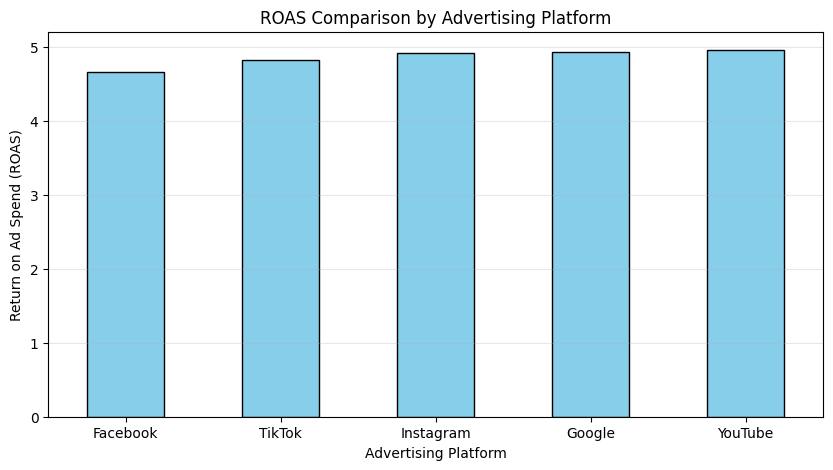

In [5]:

import matplotlib.pyplot as plt

# Create ROAS comparison chart
plt.figure(figsize=(10, 5))

platform_performance["ROAS"].sort_values().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("ROAS Comparison by Advertising Platform")
plt.xlabel("Advertising Platform")
plt.ylabel("Return on Ad Spend (ROAS)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


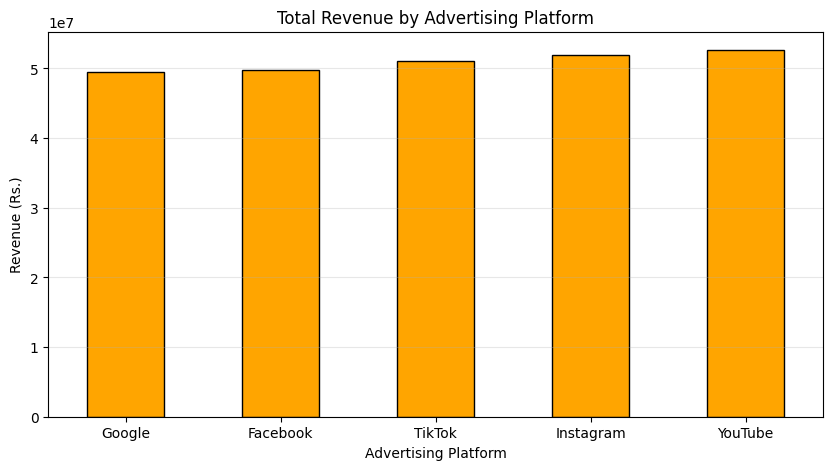

In [6]:

# Revenue comparison chart
plt.figure(figsize=(10, 5))

platform_performance["revenue"].sort_values().plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Total Revenue by Advertising Platform")
plt.xlabel("Advertising Platform")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [7]:

import time

# Generate 100,000 records
start_time = time.time()

data_100k = data.sample(
    n=100000,
    replace=True,
    random_state=42
).reset_index(drop=True)

end_time = time.time()

print("Total Records:", len(data_100k))
print("Generation Time:",
      round(end_time - start_time, 4), "seconds")

display(data_100k.head())


Total Records: 100000
Generation Time: 0.0436 seconds


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device,CTR,CPC,CPA,Conversion_Rate,ROAS
0,2025-10-30 22:00:00,Sales,Facebook,34785,85,1523,21,13927,39,Male,Lahore,Desktop,0.244358,17.917647,72.523810,24.705882,9.144452
1,2025-02-05 20:00:00,Traffic,Facebook,73043,645,9108,69,23201,54,Male,Karachi,Tablet,0.883041,14.120930,132.000000,10.697674,2.547321
2,2025-08-13 14:00:00,Traffic,Instagram,96071,718,7081,15,3292,35,Female,Faisalabad,Tablet,0.747364,9.862117,472.066667,2.089136,0.464906
3,2025-08-05 07:00:00,Traffic,Google,81138,97,621,21,36754,31,Female,Faisalabad,Tablet,0.119549,6.402062,29.571429,21.649485,59.185185
4,2025-08-27 22:00:00,Sales,YouTube,44432,673,6002,32,24881,37,Male,Karachi,Mobile,1.514674,8.918276,187.562500,4.754829,4.145452


In [8]:

import time

# Start measuring time
start_time = time.time()

# Generate 1 million records
data_1M = data_100k.sample(
    n=1000000,
    replace=True,
    random_state=42
).reset_index(drop=True)

# Stop measuring time
end_time = time.time()

print("Total Records:", len(data_1M))
print("Generation Time:",
      round(end_time - start_time, 4), "seconds")

# Display first 5 rows
display(data_1M.head())


Total Records: 1000000
Generation Time: 0.2849 seconds


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device,CTR,CPC,CPA,Conversion_Rate,ROAS
0,2025-04-19 11:00:00,Brand Awareness,Facebook,53188,661,1590,77,36196,58,Female,Islamabad,Tablet,1.242762,2.405446,20.649351,11.649017,22.764780
1,2026-01-15 15:00:00,Leads,Instagram,30730,175,5419,55,2833,35,Male,Faisalabad,Desktop,0.569476,30.965714,98.527273,31.428571,0.522790
2,2025-10-23 16:00:00,Leads,YouTube,65940,914,2268,98,10901,46,Female,Karachi,Tablet,1.386109,2.481400,23.142857,10.722101,4.806437
3,2025-10-23 23:00:00,Traffic,Instagram,85463,716,9680,40,18271,49,Female,Faisalabad,Mobile,0.837789,13.519553,242.000000,5.586592,1.887500
4,2025-05-12 15:00:00,Leads,TikTok,6207,676,1105,38,36477,50,Female,Karachi,Tablet,10.890930,1.634615,29.078947,5.621302,33.010860


In [9]:

import time
import gc

# Start measuring time
start_time = time.time()

# Generate 10 million records
data_10M = data_1M.sample(
    n=10000000,
    replace=True,
    random_state=42
).reset_index(drop=True)

# Stop measuring time
end_time = time.time()

print("Total Records:", len(data_10M))
print("Generation Time:",
      round(end_time - start_time, 2), "seconds")

# Check memory usage
memory_mb = data_10M.memory_usage(
    deep=True
).sum() / (1024 ** 2)

print("Memory Usage:",
      round(memory_mb, 2), "MB")

# Display first 5 rows
display(data_10M.head())


Total Records: 10000000
Generation Time: 5.47 seconds
Memory Usage: 3581.65 MB


,date,campaign,platform,impressions,clicks,spend,conversions,revenue,age,gender,city,device,CTR,CPC,CPA,Conversion_Rate,ROAS
0,2025-07-03 06:00:00,Leads,TikTok,94402,867,9152,66,44533,55,Male,Lahore,Desktop,0.918413,10.555940,138.666667,7.612457,4.865931
1,2025-10-04 07:00:00,Traffic,Google,13675,932,5681,88,12103,59,Female,Faisalabad,Desktop,6.815356,6.095494,64.556818,9.442060,2.130435
2,2025-12-28 05:00:00,Traffic,Facebook,76341,396,2489,69,16068,48,Male,Faisalabad,Desktop,0.518725,6.285354,36.072464,17.424242,6.455605
3,2025-05-01 10:00:00,Sales,YouTube,77133,458,7276,98,44267,33,Female,Karachi,Tablet,0.593780,15.886463,74.244898,21.397380,6.083975
4,2025-12-16 16:00:00,Traffic,Instagram,41770,727,3046,16,33955,57,Female,Karachi,Tablet,1.740484,4.189821,190.375000,2.200825,11.147406


In [11]:

# Define all four datasets
datasets = {
    "10K": data,
    "100K": data_100k,
    "1M": data_1M,
    "10M": data_10M
}

print("Datasets defined successfully!")


Datasets defined successfully!


In [12]:

import time
import pandas as pd
from collections import defaultdict

# MapReduce simulation
def mapreduce_revenue(df):

    # MAP: Extract platform and revenue
    mapped = zip(df["platform"], df["revenue"])

    # REDUCE: Sum revenue for each platform
    result = defaultdict(int)

    for platform, revenue in mapped:
        result[platform] += revenue

    return dict(result)


# Test on all four datasets
mapreduce_results = []

for name, df in datasets.items():

    start = time.perf_counter()

    result = mapreduce_revenue(df)

    end = time.perf_counter()

    processing_time = end - start

    mapreduce_results.append({
        "Dataset": name,
        "Records": len(df),
        "MapReduce_Time": processing_time
    })

    print(name, ":", round(processing_time, 4), "seconds")

# Display results
mapreduce_results_df = pd.DataFrame(mapreduce_results)

display(mapreduce_results_df)


10K : 0.01 seconds
100K : 0.0802 seconds
1M : 0.7617 seconds
10M : 3.9863 seconds


,Dataset,Records,MapReduce_Time
0,10K,10000,0.010007
1,100K,100000,0.080245
2,1M,1000000,0.761690
3,10M,10000000,3.986295


In [13]:
!pip -q install pyspark

In [14]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("BDA_Advertising_Optimizer") \
    .master("local[2]") \
    .config("spark.driver.memory", "2g") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("Apache Spark Started Successfully!")


Apache Spark Started Successfully!


In [15]:

import time
from pyspark.sql import functions as F

# Use only the columns needed
spark_data = spark.createDataFrame(
    data[["platform", "revenue"]]
)

# Measure processing time
start = time.perf_counter()

result = spark_data.groupBy("platform").agg(
    F.sum("revenue").alias("total_revenue")
)

result.show()

end = time.perf_counter()

print("Spark Processing Time:",
      round(end - start, 4), "seconds")



+---------+-------------+
| platform|total_revenue|
+---------+-------------+
|  YouTube|     52637256|
|   TikTok|     51033917|
|Instagram|     51966593|
|   Google|     49425829|
| Facebook|     49740264|
+---------+-------------+

Spark Processing Time: 5.8135 seconds


In [16]:

import time
import pandas as pd
from pyspark.sql import functions as F

spark_results = []

# Test all dataset sizes
for name, df in datasets.items():

    print("Processing:", name)

    # Convert only required columns to Spark
    spark_df = spark.createDataFrame(
        df[["platform", "revenue"]]
    )

    # Start timing
    start = time.perf_counter()

    result = spark_df.groupBy("platform").agg(
        F.sum("revenue").alias("total_revenue")
    )

    # Execute Spark calculation
    result.collect()

    end = time.perf_counter()

    spark_results.append({
        "Dataset": name,
        "Records": len(df),
        "Spark_Time": end - start
    })

    print("Completed:", name)
    print("--------------------")

# Show results
spark_results_df = pd.DataFrame(spark_results)

display(spark_results_df.round(4))


Processing: 10K
Completed: 10K
--------------------
Processing: 100K
Completed: 100K
--------------------
Processing: 1M
Completed: 1M
--------------------
Processing: 10M
Completed: 10M
--------------------


,Dataset,Records,Spark_Time
0,10K,10000,0.9923
1,100K,100000,0.7732
2,1M,1000000,2.4797
3,10M,10000000,15.7282


In [19]:
# Compare Pandas, MapReduce and Spark
# Define the base comparison DataFrame from MapReduce results first
comparison = mapreduce_results_df

final_comparison = comparison.merge(
    spark_results_df,
    on=["Dataset", "Records"]
)

display(final_comparison.round(4))

,Dataset,Records,MapReduce_Time,Spark_Time
0,10K,10000,0.0100,0.9923
1,100K,100000,0.0802,0.7732
2,1M,1000000,0.7617,2.4797
3,10M,10000000,3.9863,15.7282


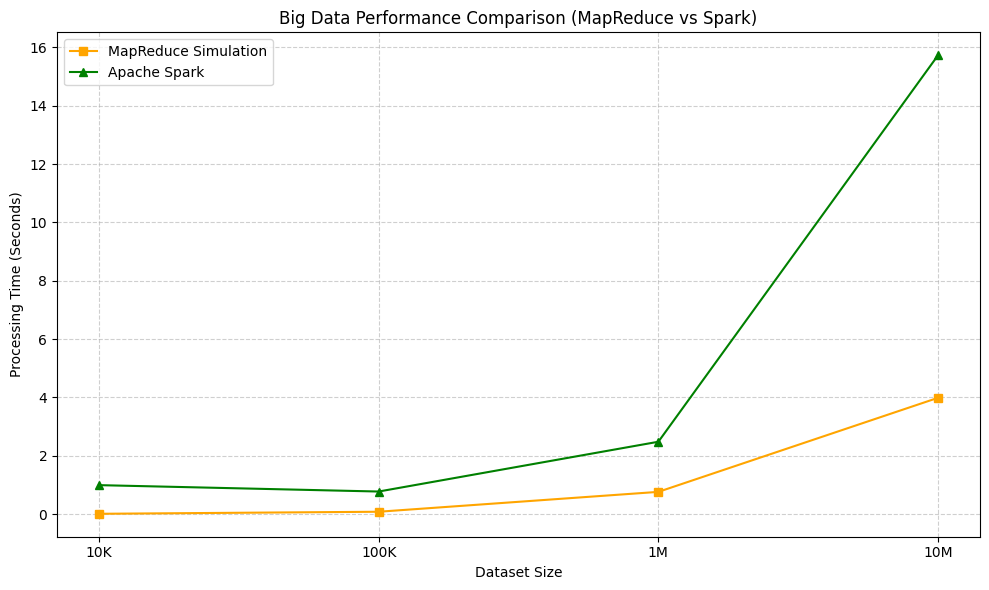

In [21]:
import matplotlib.pyplot as plt

# Arrange dataset sizes
order = ["10K", "100K", "1M", "10M"]

# final_comparison is already defined from the previous cell
graph_data = final_comparison.set_index(
    "Dataset"
).loc[order]

# Create graph
plt.figure(figsize=(10, 6))

plt.plot(
    graph_data.index,
    graph_data["MapReduce_Time"],
    marker="s",
    color="orange",
    label="MapReduce Simulation"
)

plt.plot(
    graph_data.index,
    graph_data["Spark_Time"],
    marker="^",
    color="green",
    label="Apache Spark"
)

plt.title("Big Data Performance Comparison (MapReduce vs Spark)")
plt.xlabel("Dataset Size")
plt.ylabel("Processing Time (Seconds)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [22]:

# Step 9: Marketing Budget Recommendation Engine

# Total advertising budget
total_budget = 1000000

# Get platform performance
budget_data = platform_performance.copy()

# Calculate budget weights based on ROAS
budget_data["Weight"] = (
    budget_data["ROAS"] /
    budget_data["ROAS"].sum()
)

# Calculate budget percentage
budget_data["Budget_Percentage"] = (
    budget_data["Weight"] * 100
)

# Allocate budget in Pakistani Rupees
budget_data["Recommended_Budget"] = (
    budget_data["Weight"] * total_budget
)

# Display recommendation
recommendations = budget_data[[
    "ROAS",
    "Budget_Percentage",
    "Recommended_Budget"
]].sort_values(
    "Recommended_Budget",
    ascending=False
)

display(recommendations.round(2))

print("Total Recommended Budget: Rs.",
      round(recommendations["Recommended_Budget"].sum()))


,ROAS,Budget_Percentage,Recommended_Budget
platform,,,
YouTube,4.96,20.41,204140.61
Google,4.93,20.28,202795.42
Instagram,4.93,20.27,202690.83
TikTok,4.83,19.87,198679.06
Facebook,4.66,19.17,191694.08


Total Recommended Budget: Rs. 1000000


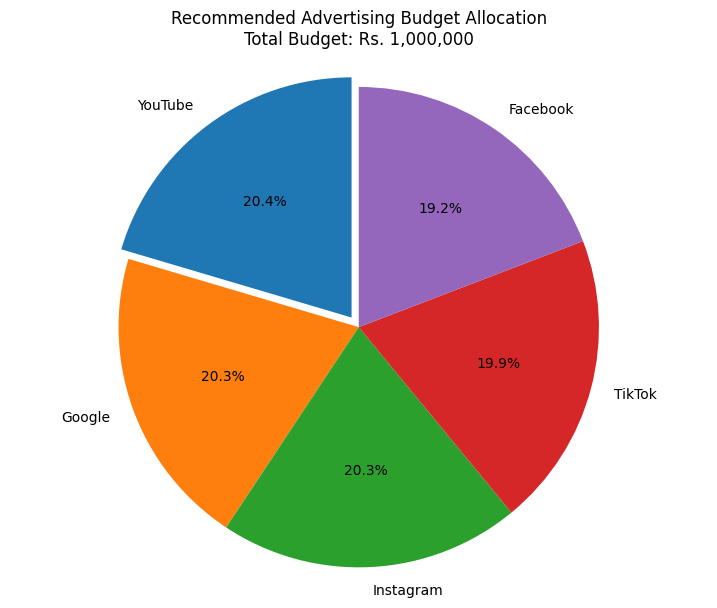

In [23]:

import matplotlib.pyplot as plt

# Create budget allocation pie chart
plt.figure(figsize=(9, 7))

plt.pie(
    recommendations["Budget_Percentage"],
    labels=recommendations.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05] + [0] * (len(recommendations) - 1)
)

plt.title(
    "Recommended Advertising Budget Allocation\n"
    "Total Budget: Rs. 1,000,000"
)

plt.axis("equal")
plt.show()


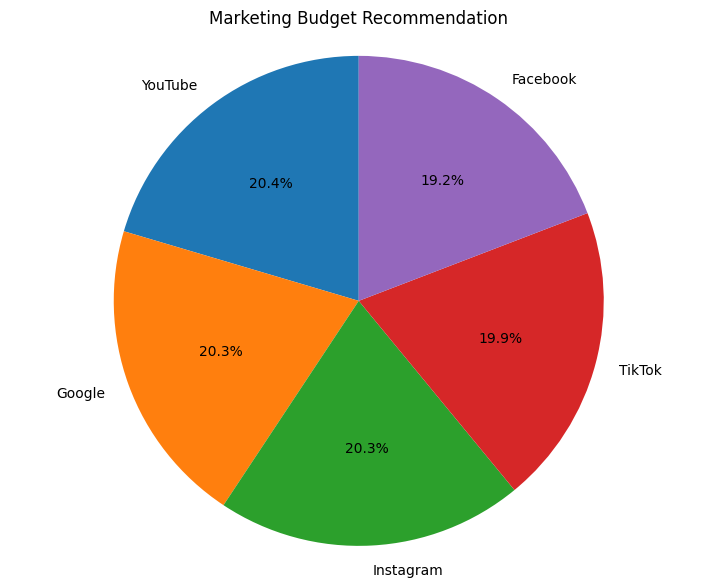

Chart saved successfully!


In [24]:

plt.figure(figsize=(9, 7))

plt.pie(
    recommendations["Budget_Percentage"],
    labels=recommendations.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Marketing Budget Recommendation")
plt.axis("equal")

plt.savefig(
    "Budget_Allocation_Chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


In [25]:

# Step 11: Final project verification

print("===== BDA PROJECT SUMMARY =====")

print("\nDataset Sizes:")
for name, df in datasets.items():
    print(name, ":", len(df), "records")

print("\nBest Advertising Platform:")
print(platform_performance["ROAS"].idxmax())

print("\nTotal Budget Allocated:")
print("Rs.", recommendations["Recommended_Budget"].sum())

print("\nBudget Percentage Total:")
print(round(recommendations["Budget_Percentage"].sum(), 2), "%")

print("\nPerformance Comparison:")
display(final_comparison.round(4))

print("\nBudget Recommendations:")
display(recommendations.round(2))


===== BDA PROJECT SUMMARY =====

Dataset Sizes:
10K : 10000 records
100K : 100000 records
1M : 1000000 records
10M : 10000000 records

Best Advertising Platform:
YouTube

Total Budget Allocated:
Rs. 1000000.0

Budget Percentage Total:
100.0 %

Performance Comparison:


,Dataset,Records,MapReduce_Time,Spark_Time
0,10K,10000,0.0100,0.9923
1,100K,100000,0.0802,0.7732
2,1M,1000000,0.7617,2.4797
3,10M,10000000,3.9863,15.7282



Budget Recommendations:


,ROAS,Budget_Percentage,Recommended_Budget
platform,,,
YouTube,4.96,20.41,204140.61
Google,4.93,20.28,202795.42
Instagram,4.93,20.27,202690.83
TikTok,4.83,19.87,198679.06
Facebook,4.66,19.17,191694.08
